In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Мощность теста

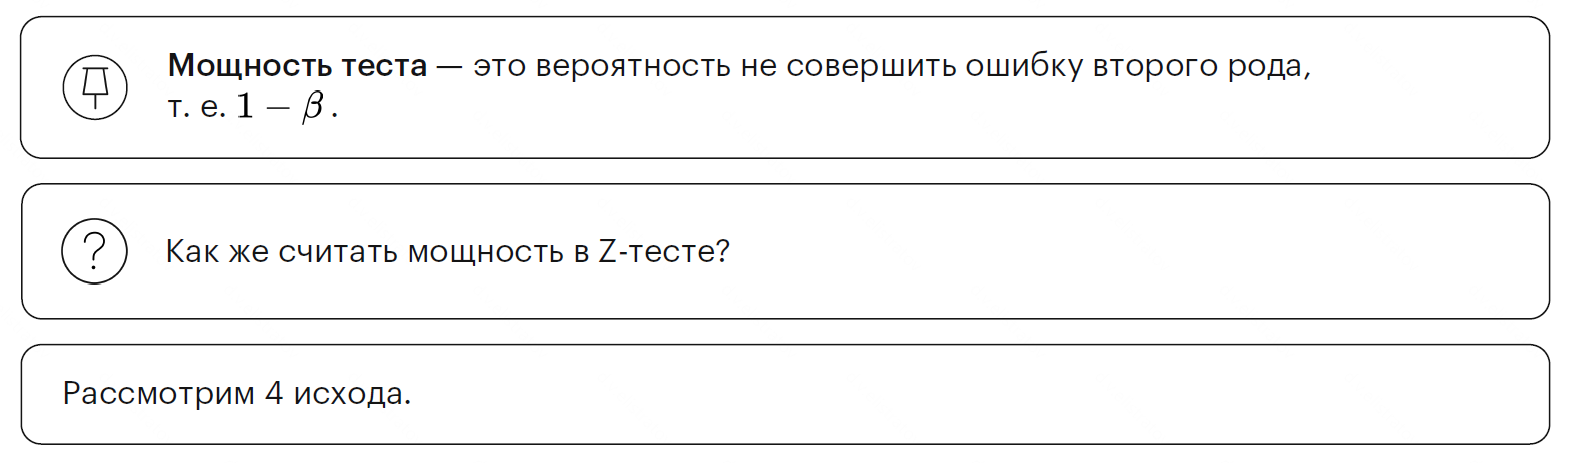

## 4 исхода теста

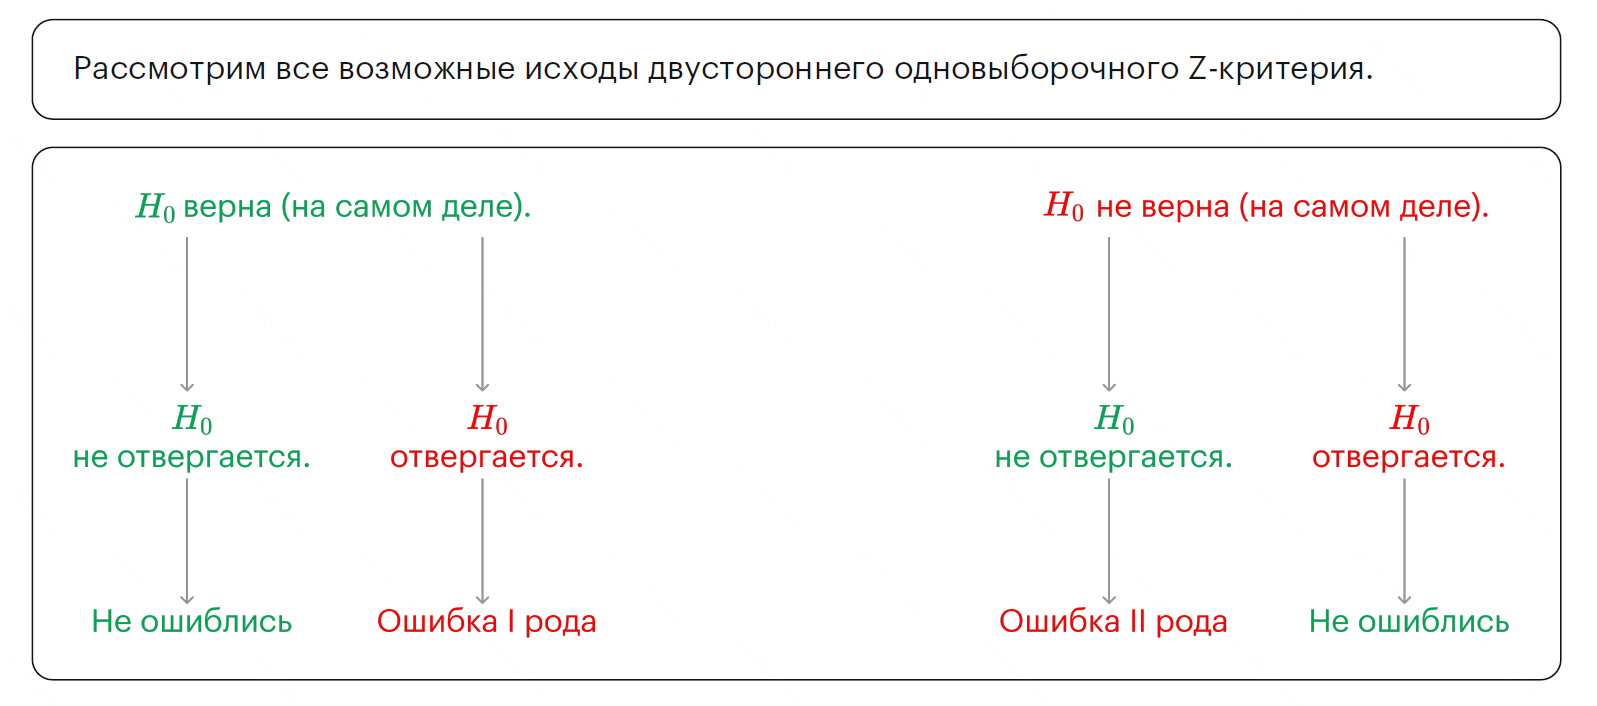

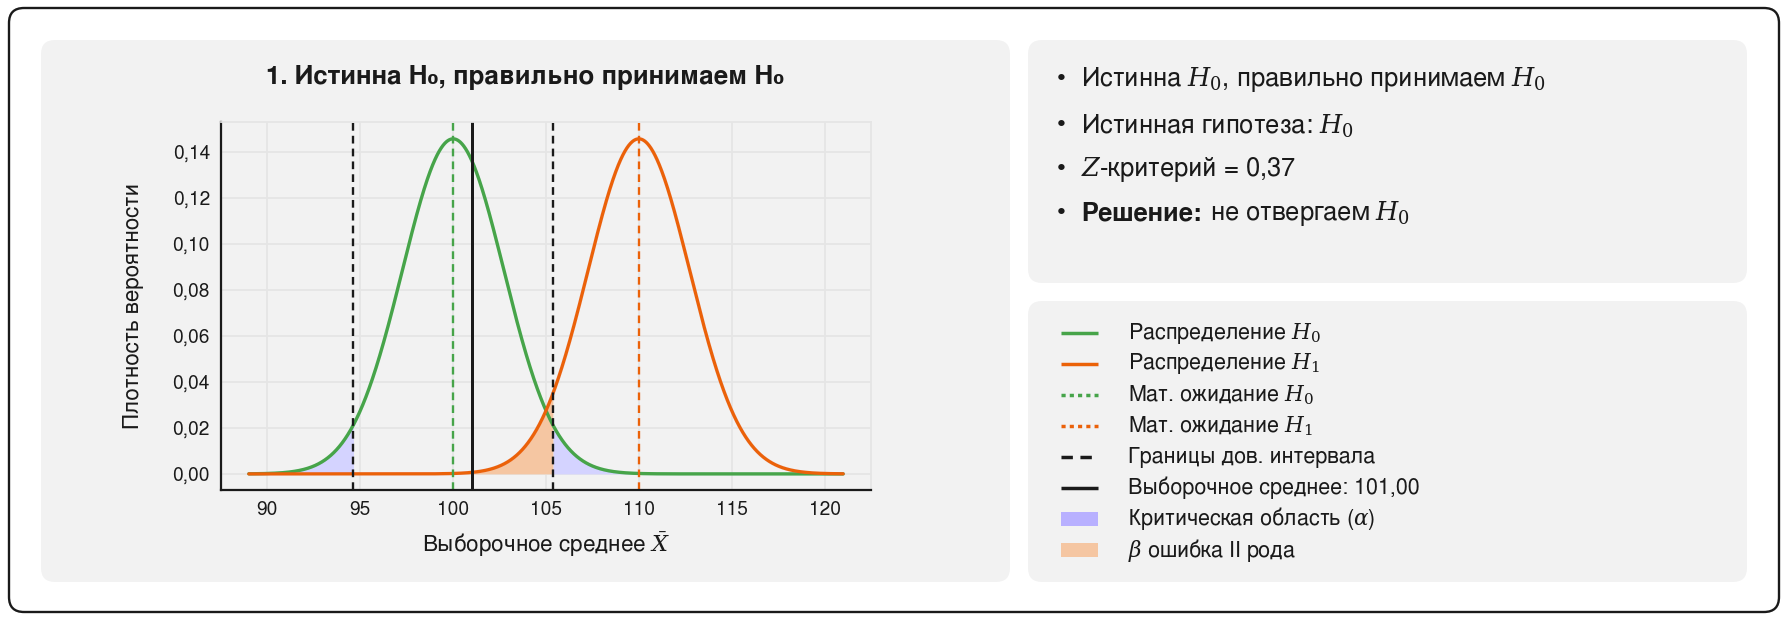

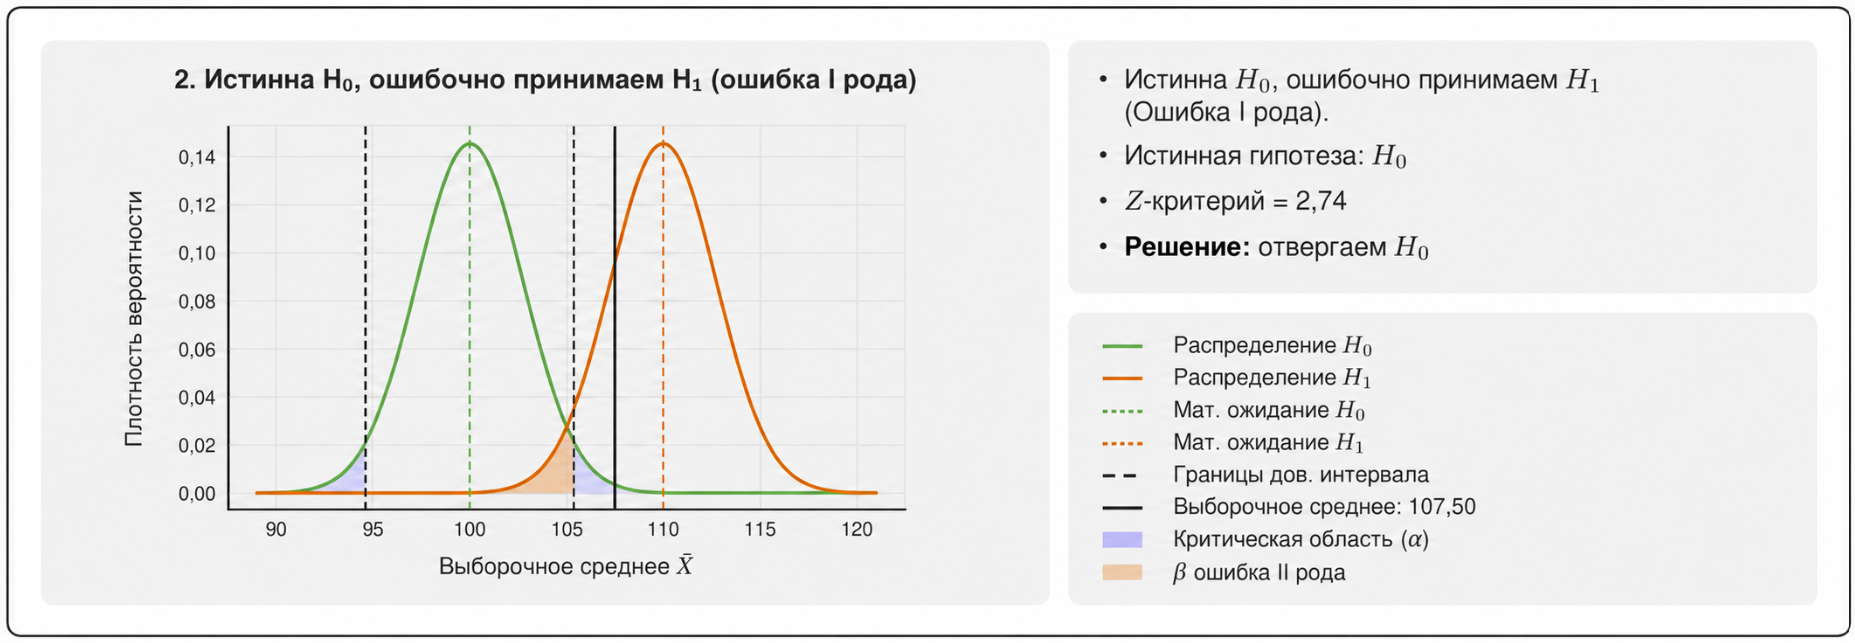

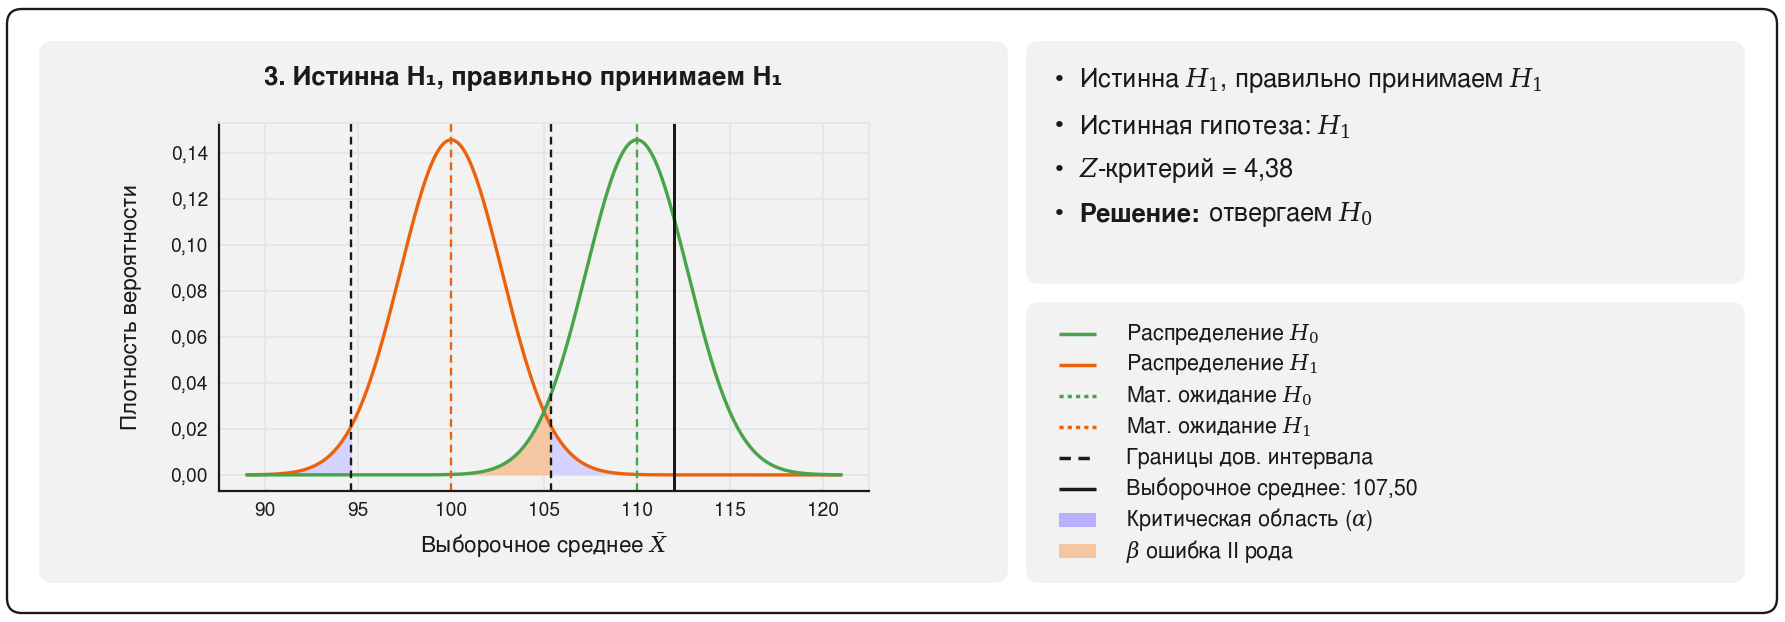

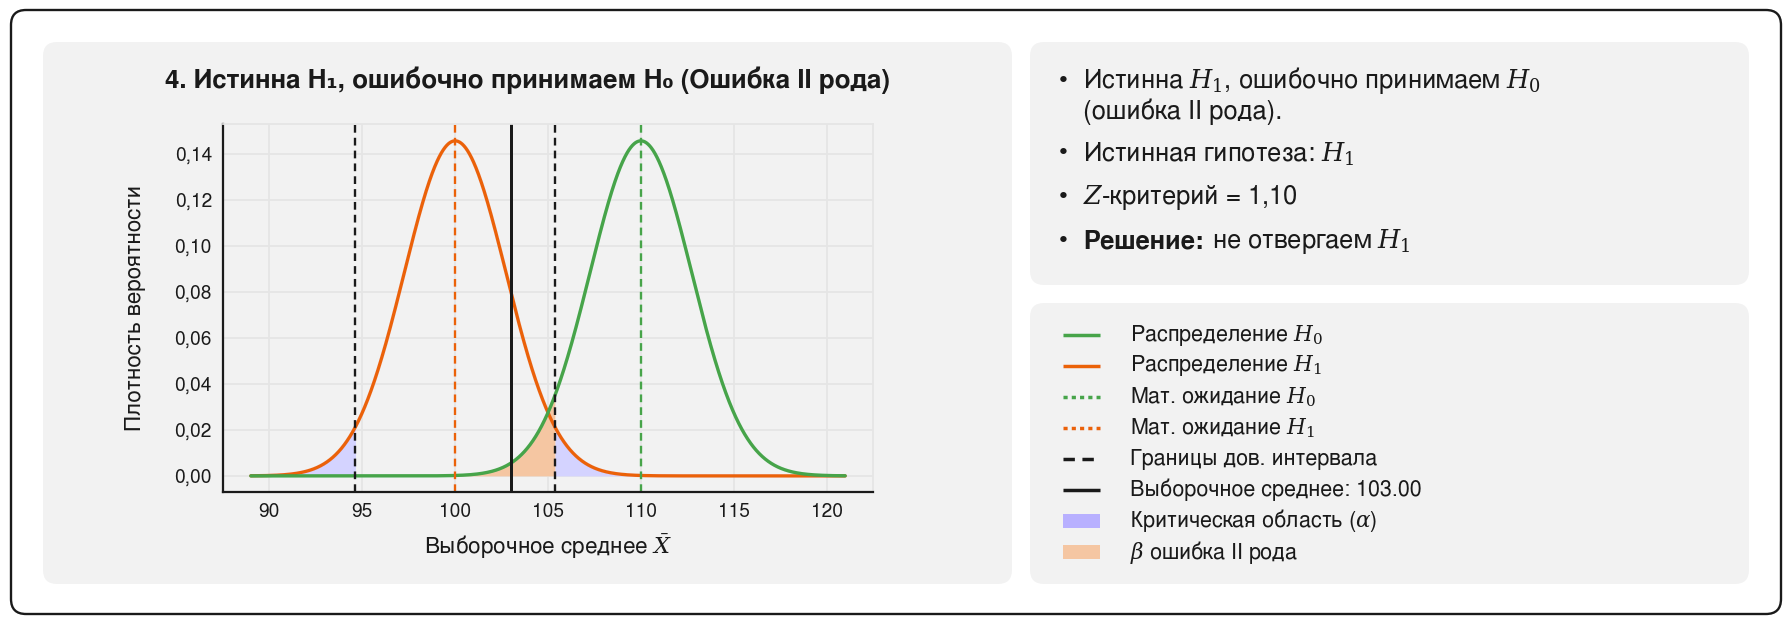

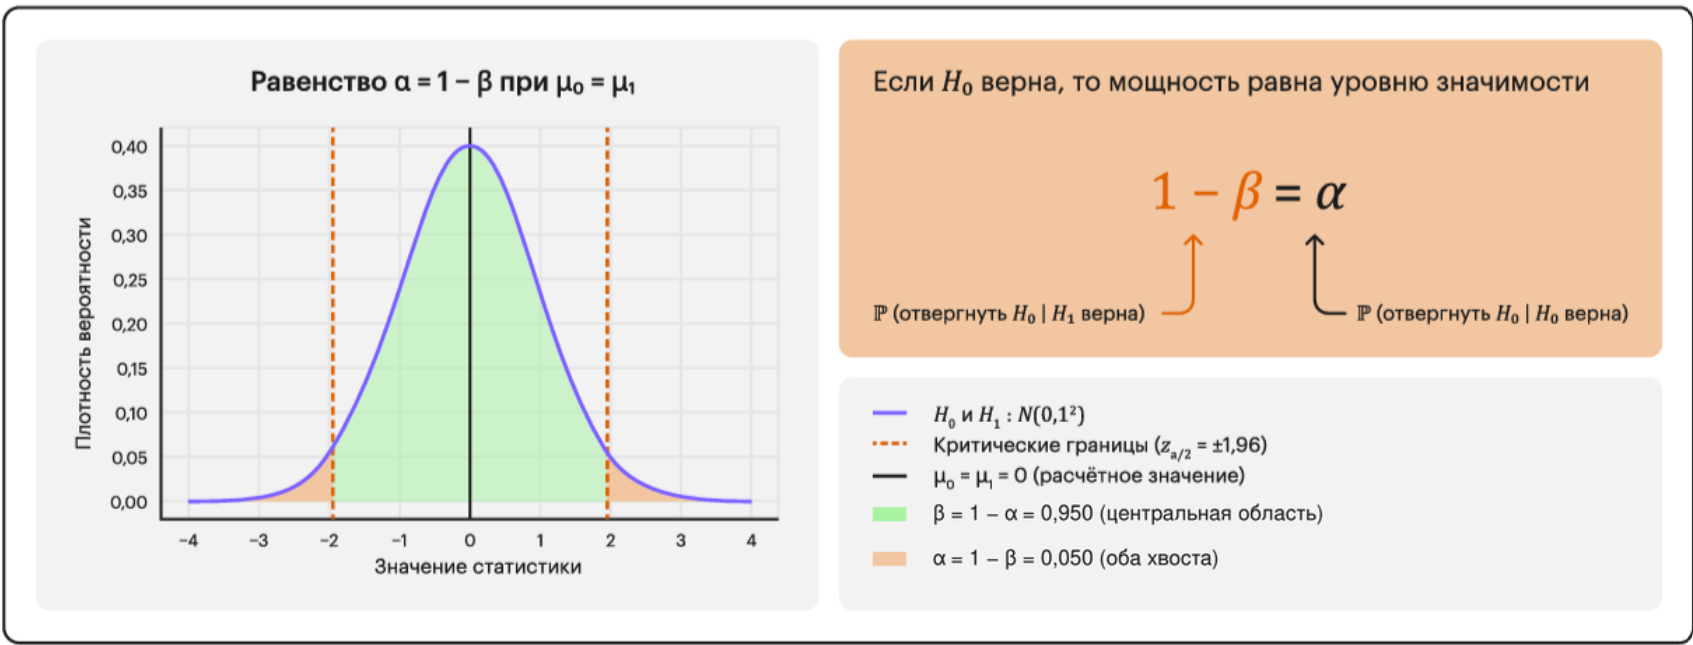

# MDE и Sample size

## Алгоритм расчёта необходимого количества наблюдений

**Пункт 0**
 - Предположим, что мы хотим провести эксперимент который принесет какое-то изменение в продукт. С точки зрения статистики это наш *наблюдаемый эффект*  $\overline{x}_t - \overline{x}_c$.
 - Обычно это *минимальная бизнесовозначимая разница, которую мы хотим задетектировать* или же **MDE (Minimum Detectable Effect)**. Таким образом, получаем $$\operatorname{MDE} = \overline{x}_t - \overline{x}_c$$.


**Пункт 1**
 - С точки зрения левого распределения можем обозначить $z_{\text{crit}} = z_{1-\frac{\alpha}{2}}$
 - С точки зрения правого распределения можем обозначить $z_{\text{crit}} = z_{\beta}$


**Пункт 2**

Стандартзация рассчитывается по следующей формуле:
$$z = \frac{x_i-\mu}{SE}$$ где $$SE = \frac{\sigma_x}{\sqrt{n}}$$

Нам же надо из $z$-значения обратно перейти к $x_i$. Выразим:

$$x_i=z \cdot SE + \mu$$ где $\mu$ - мат.ожидание распределения.


**Пункт 3**

Тогда $x_{\text{crit}}=z_{\text{crit}} \cdot SE + \mu$

Выразим $x_{\text{crit}}$ с точки зрения левого и правого распределений:

$$\begin{equation}
    \begin{cases}
      x_{\text{crit}}=z_{1-\frac{\alpha}{2}} \cdot \sqrt{\frac{\sigma^2_t+\sigma^2_c}{n}} + 0\\
      x_{\text{crit}}=z_{\beta} \cdot \sqrt{\frac{\sigma^2_t+\sigma^2_c}{n}} + MDE
    \end{cases}\
\end{equation}
$$

Так как рассчитанное среднее не отличается для левого и правого распределений, можем приравнять правые части двух уравнений:

$$n = \frac{(\sigma^2_t+\sigma^2_c) \cdot (z_{\alpha /2 }+z_{1-\beta})^2}{MDE^2}$$

**Вывод:**
Такая формула описывает взаимосвязь между желаемым минимальным детектируемым эффектом (MDE) и числом пользователей, которое потребуется набрать в эксперименте.
Либо наоборот, от числа доступных пользователей за определенный период определить MDE.

## Формула расчёта необходимого количества наблюдений

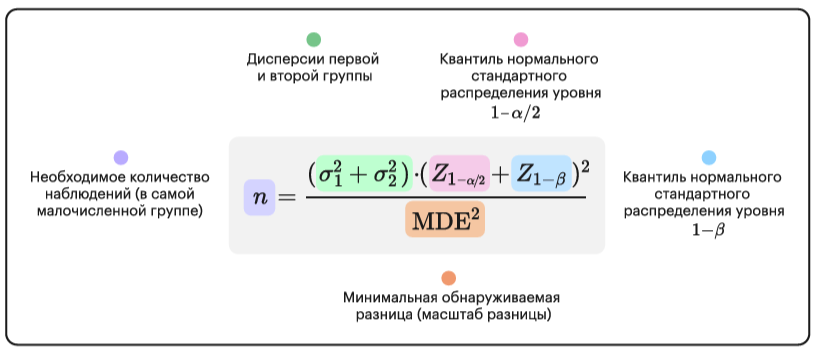

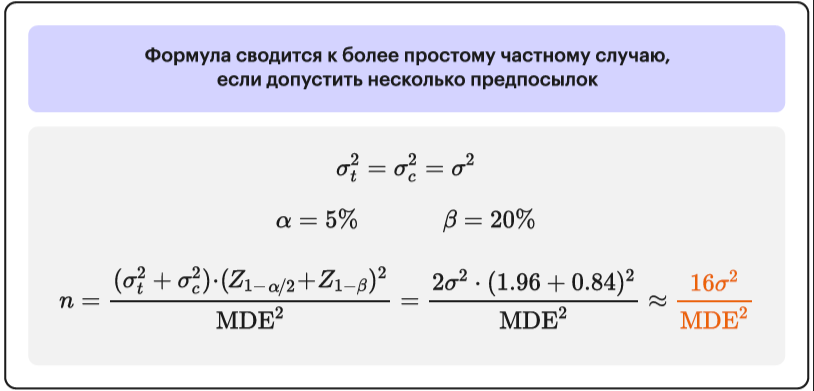

# Зависимости в формуле дизайна A/B теста

## Зависимость мощности от $\mu_1$

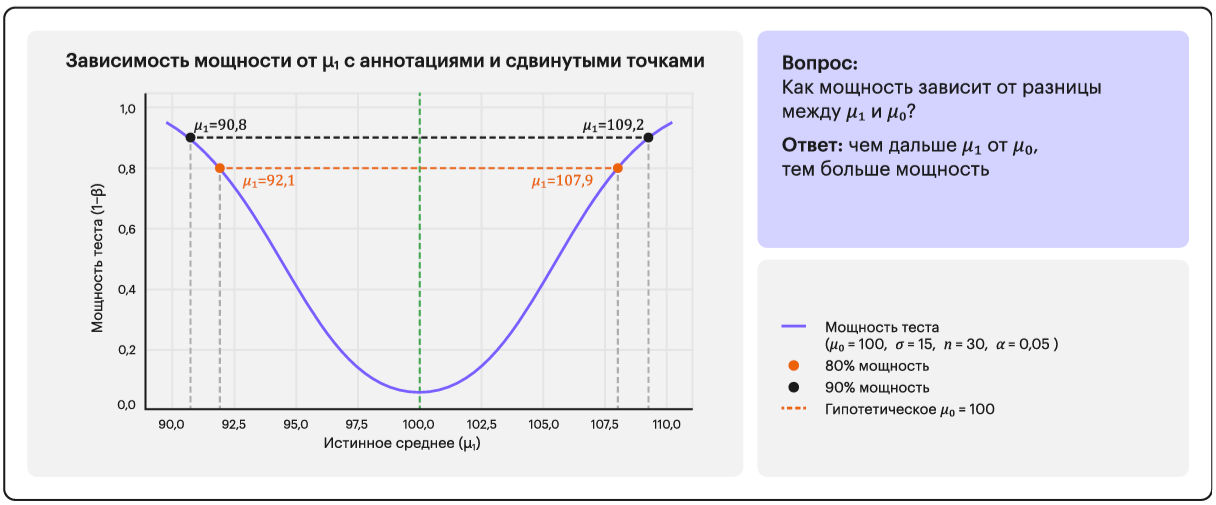

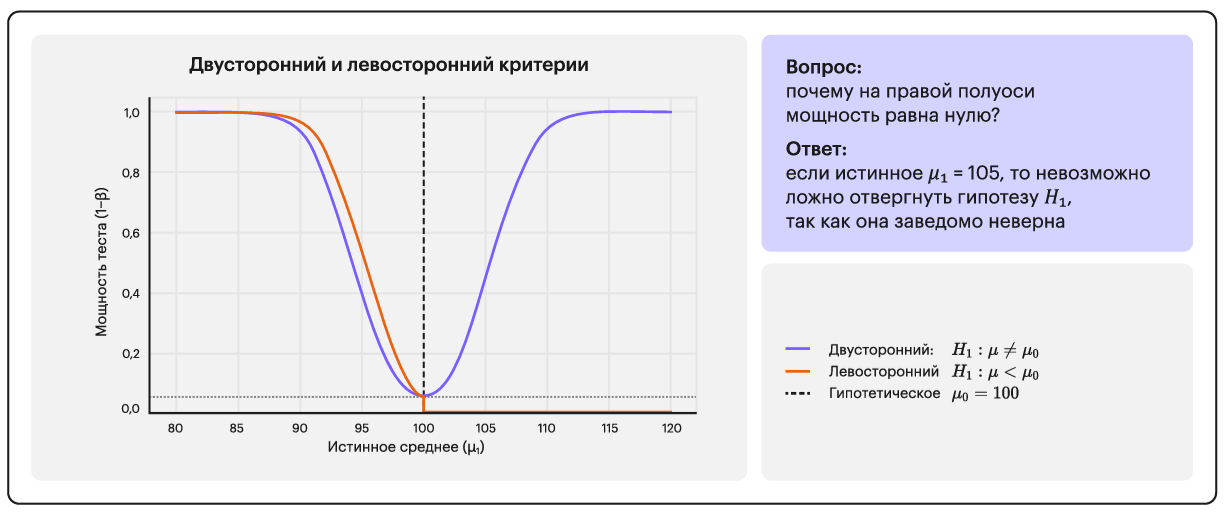

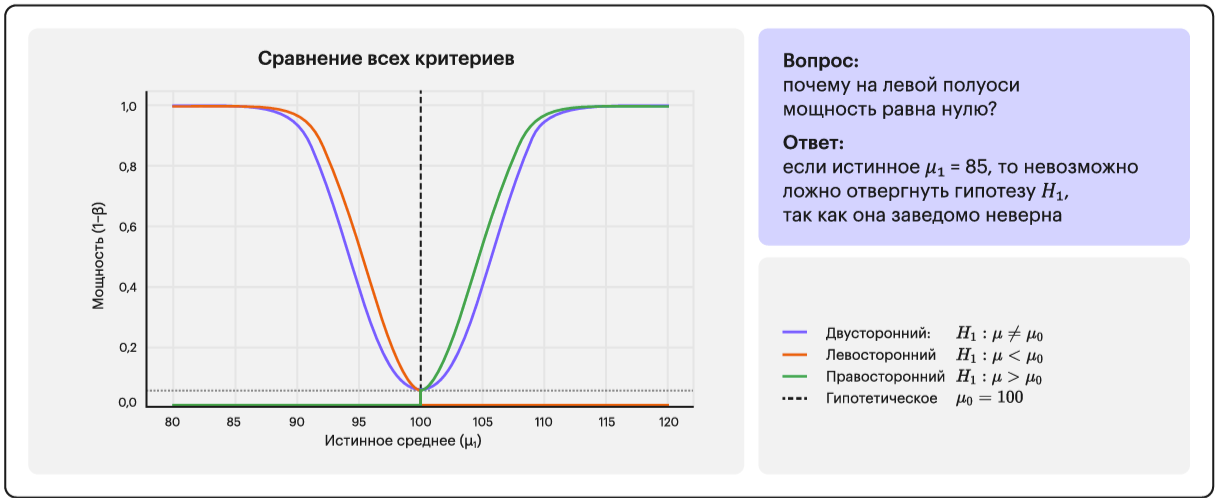

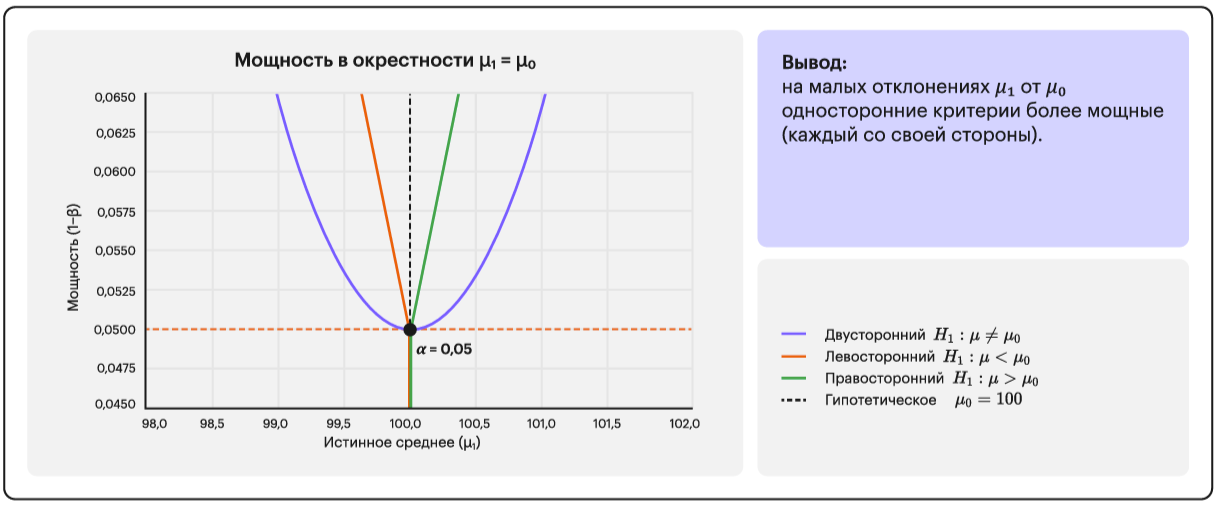

## Зависимость мощности от размера выборки

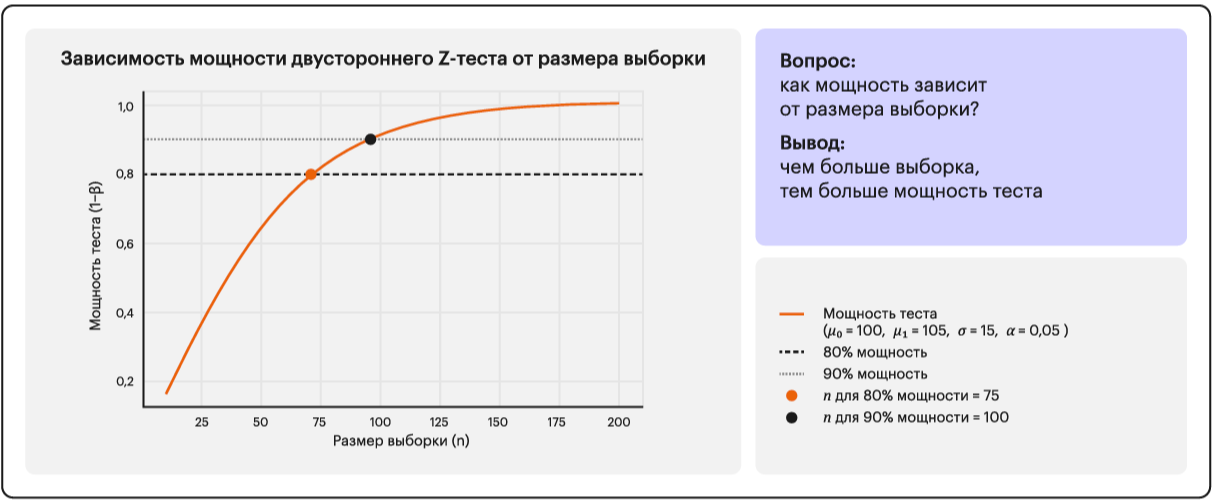

## Зависимость мощности от дисперсии выборки

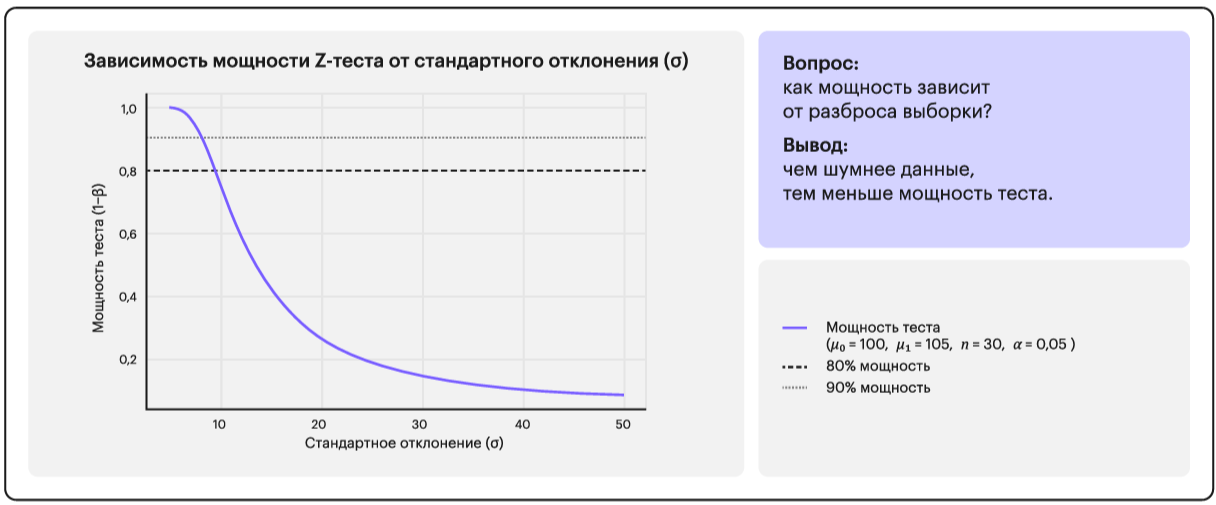

# Мощность теста для выборок Бернулли

### Правосторонний критерий

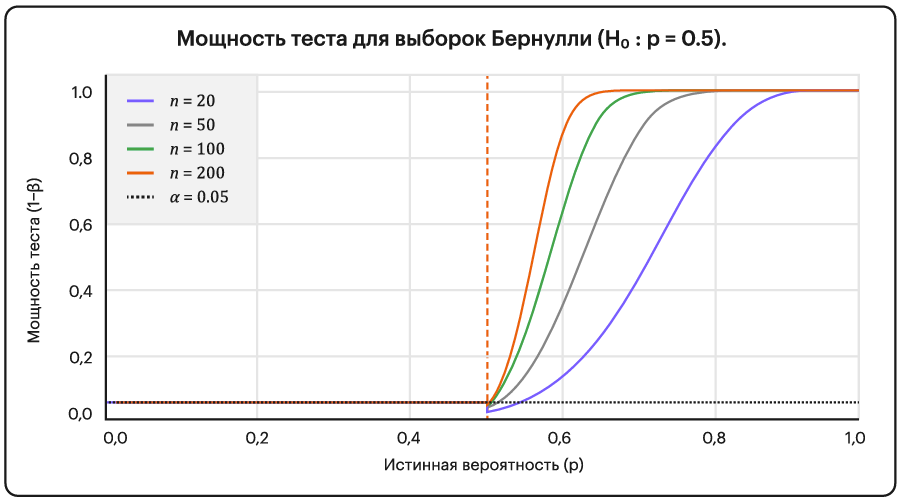

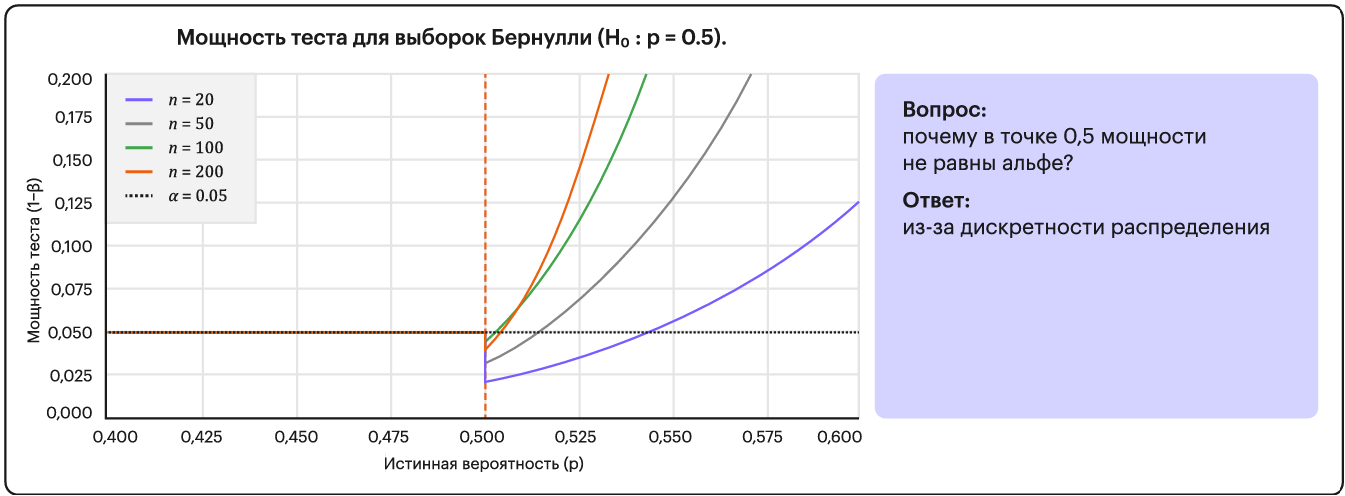

### Левосторонний критерий

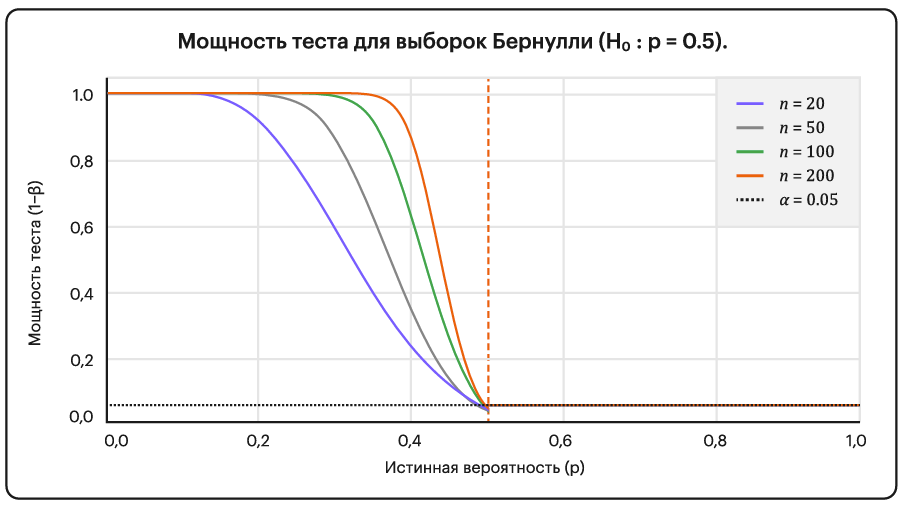

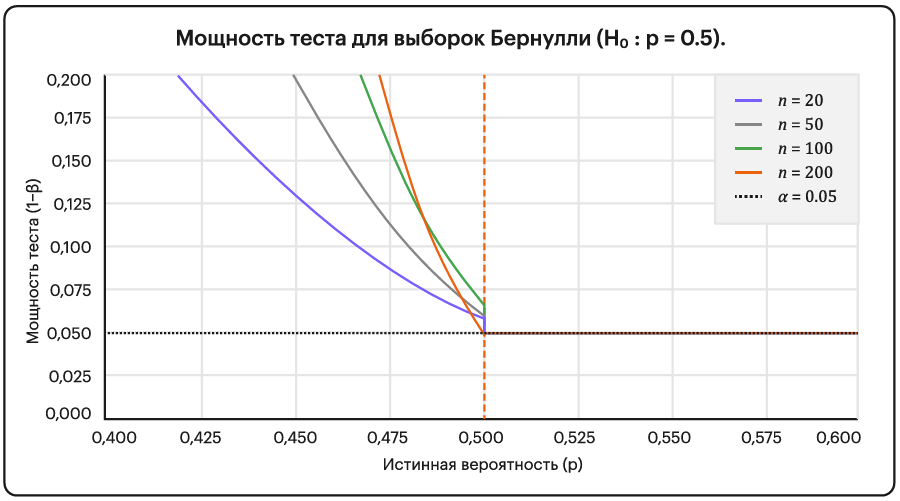

### Двусторонний критерий

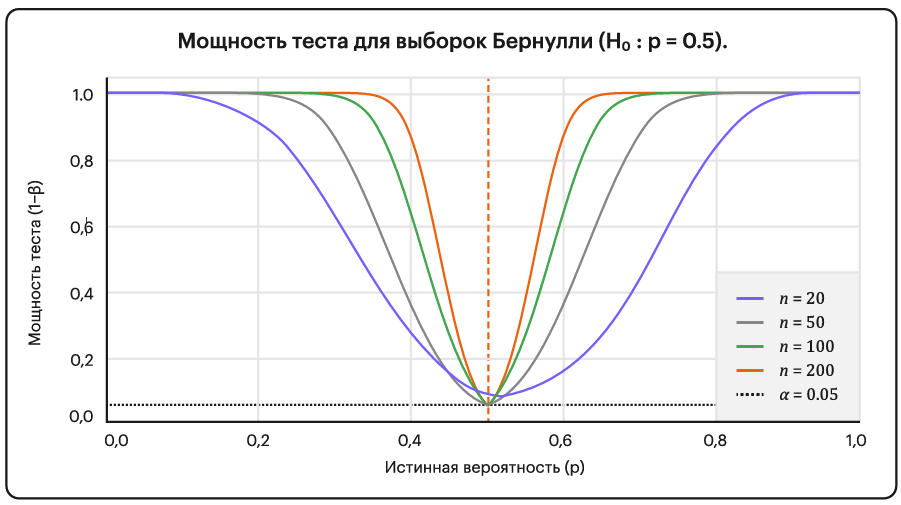

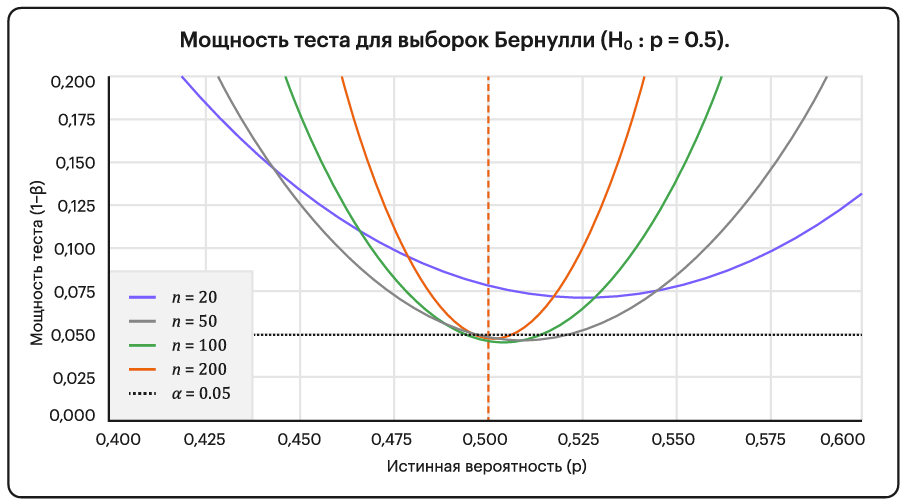

### Зависимость мощности теста для выборок Бернулли от объема выборки

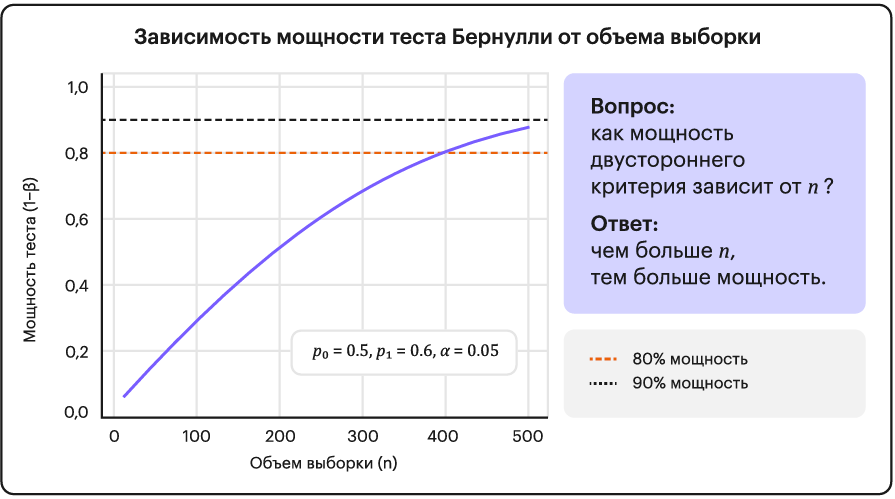

# Дизайн эксперимента

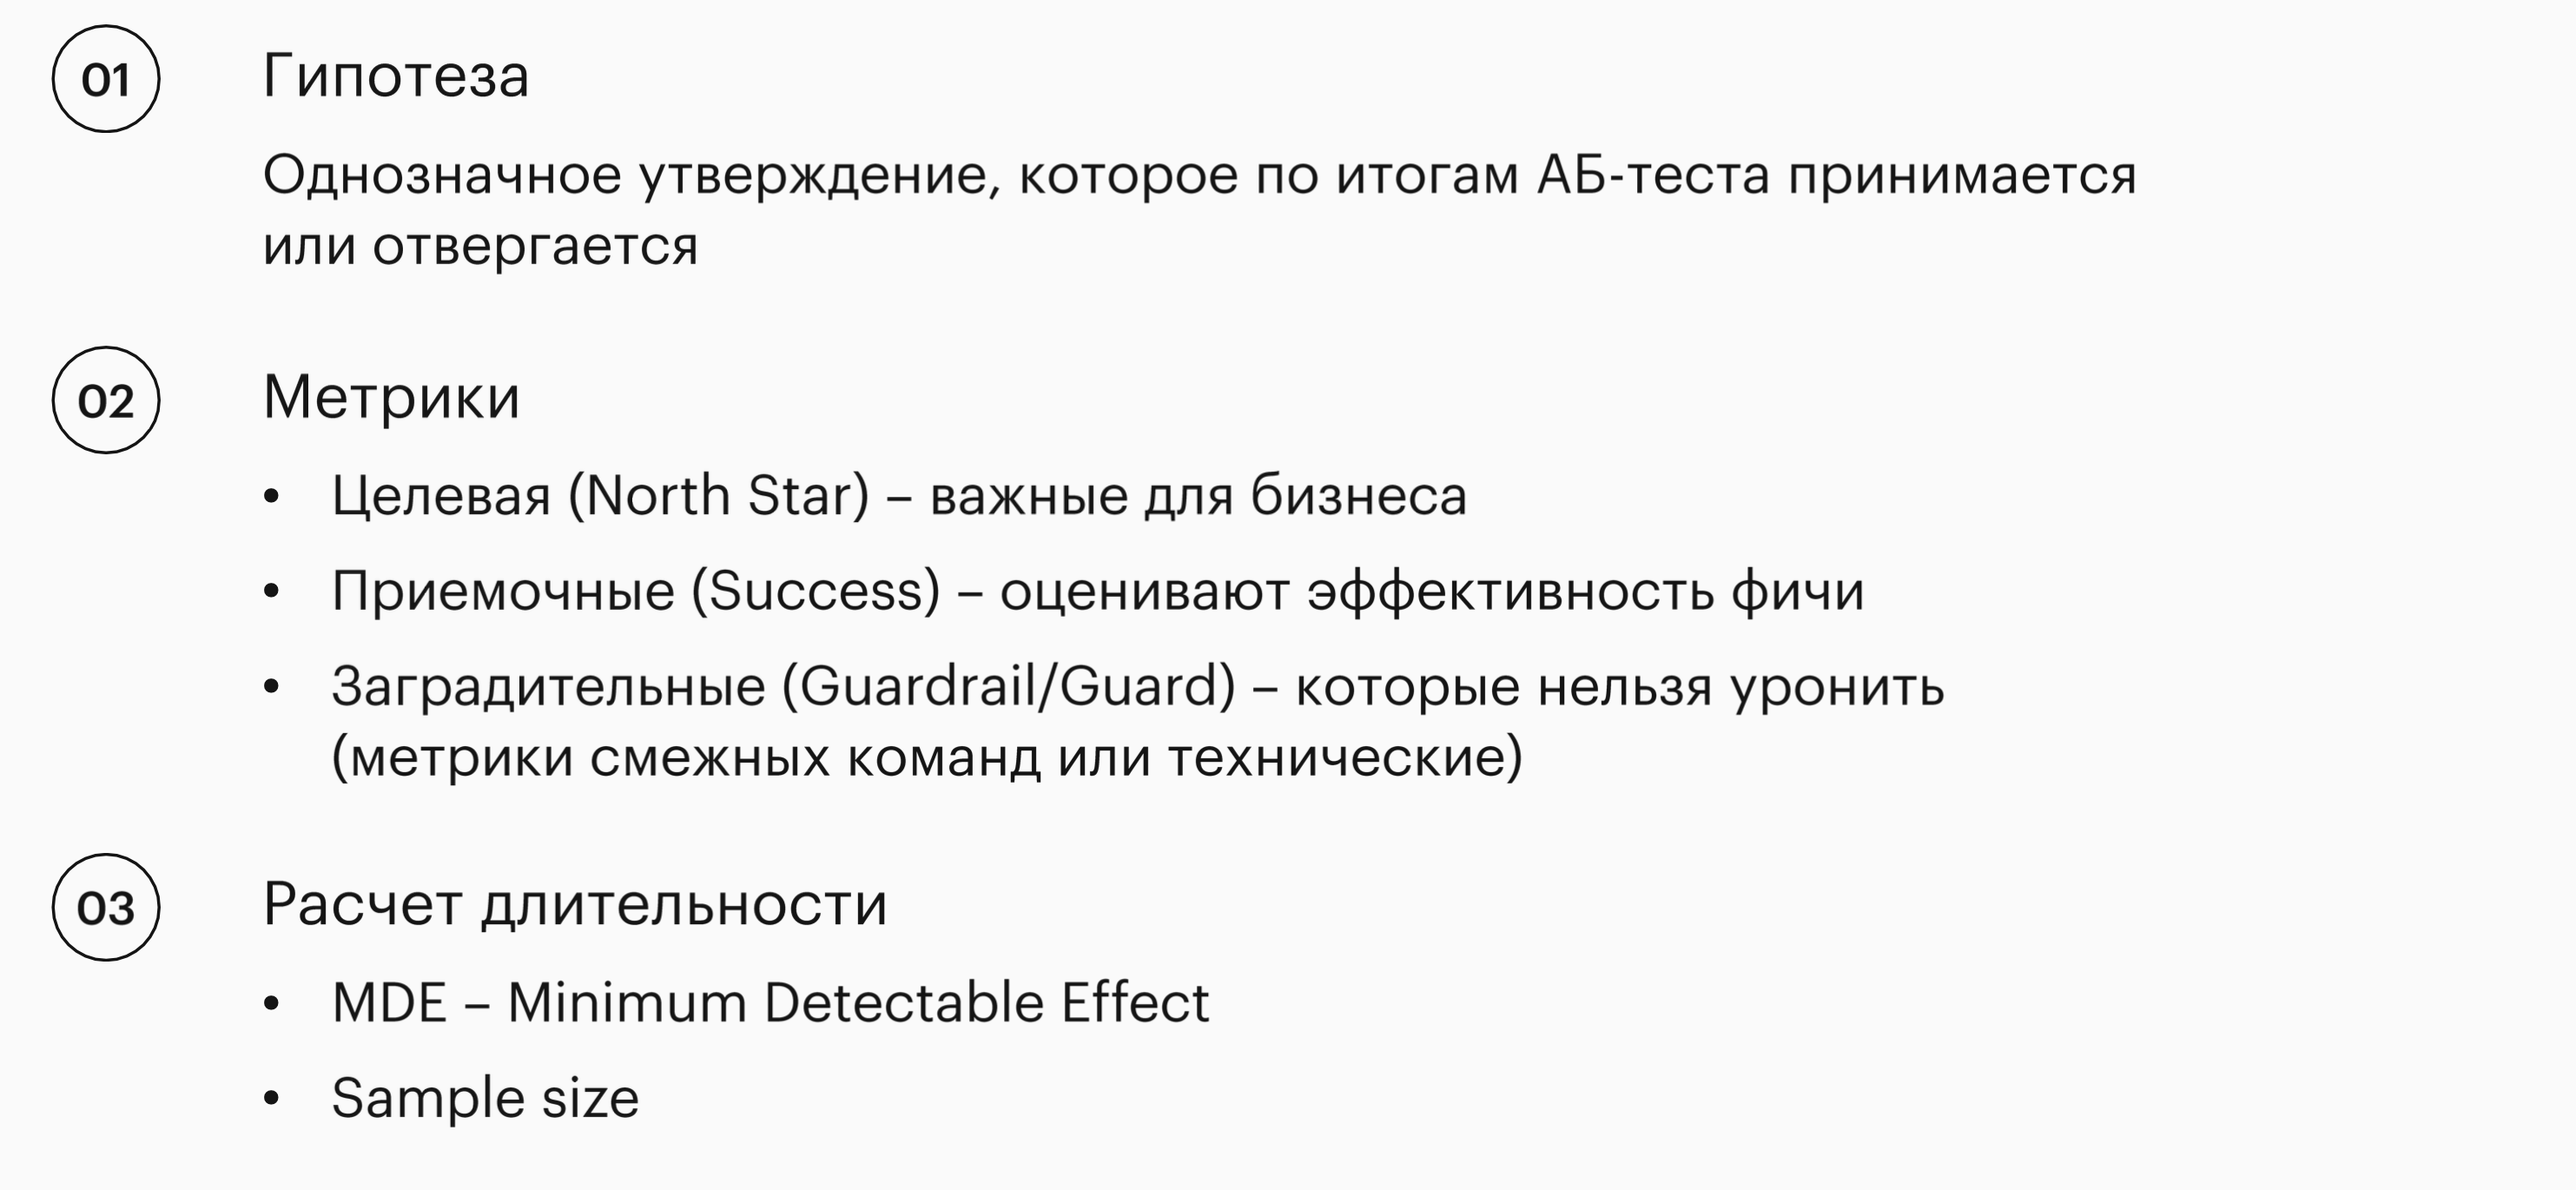

## Пример 1. Дизайн от MDE

**Рассмотрим пример**

Мы планируем изменить дизайн лендинга и таким образом увеличить конверсию из захода в покупку.

Минимальный бизнесово значимый эффект (он же MDE) составит 2 процентных пункта.


**Гипотеза:** Изменение дизайна лендинга увеличит конверсию пользователей в следующие этапы воронки, что в итоге увеличит конверсию в покупку

**Метрики:**
 - Целевые: Конверсия пользователей в покупку, GMV на пользователе
 - Приемочные: Конверсия в каталог товаров



 **Расчет длительности** давайте разберем ниже отдельно

Мы оценили конверсию из захода в покупку за прошлые 2 недели и она составила $12.3\%$.

Сколько всего наблюдений нам потребуется в рамках A/B теста, чтобы *разглядеть* статистически значимую разницу, равную или больше, чем *MDE*.

In [ ]:
mde = 0.02

p_old = 0.123
var_old = p_old * (1-p_old)  # по Бернулли

p_new = p_old + mde
var_new = p_new * (1-p_new)

print("Сигма А = ", var_old)
print("Сигма B = ", var_new)

Сигма А =  0.107871
Сигма B =  0.122551


**Можно ли использовать предпосылку о равенстве сигм в группах А и В?**

In [ ]:
n_old = int(16 * var_old / mde**2)
n_new = int(16 * var_new / mde**2)

print(n_old, n_new)

4314 4902


In [ ]:
f'Потребуется {2 * max(n_old, n_new)} пользователей'

'Потребуется 9804 пользователей'

## Пример 2. Дизайн от n

In [ ]:
N = 15000       # всего пользователей
n = N // 2      # пользователей в каждой группе

p_old = 0.123
var_old = p_old * (1 - p_old)

In [ ]:
mde_abs = np.sqrt(16 * var_old / n)
mde_prc = mde_abs / p_old

print(f"Абсолютный MDE: {100 * mde_abs:.2f} п.п.")
print(f"Относительный MDE: {100 * mde_prc:.2f}%")

Абсолютный MDE: 1.52 п.п.
Относительный MDE: 12.33%


In [ ]:
p_new = p_old + mde_abs

print(f"Исходная конверсия: {100 * p_old:.2f}%")
print(f"Конверсия при росте на MDE: {100 * p_new:.2f}%")

Исходная конверсия: 12.30%
Конверсия при росте на MDE: 13.82%


## Вывод

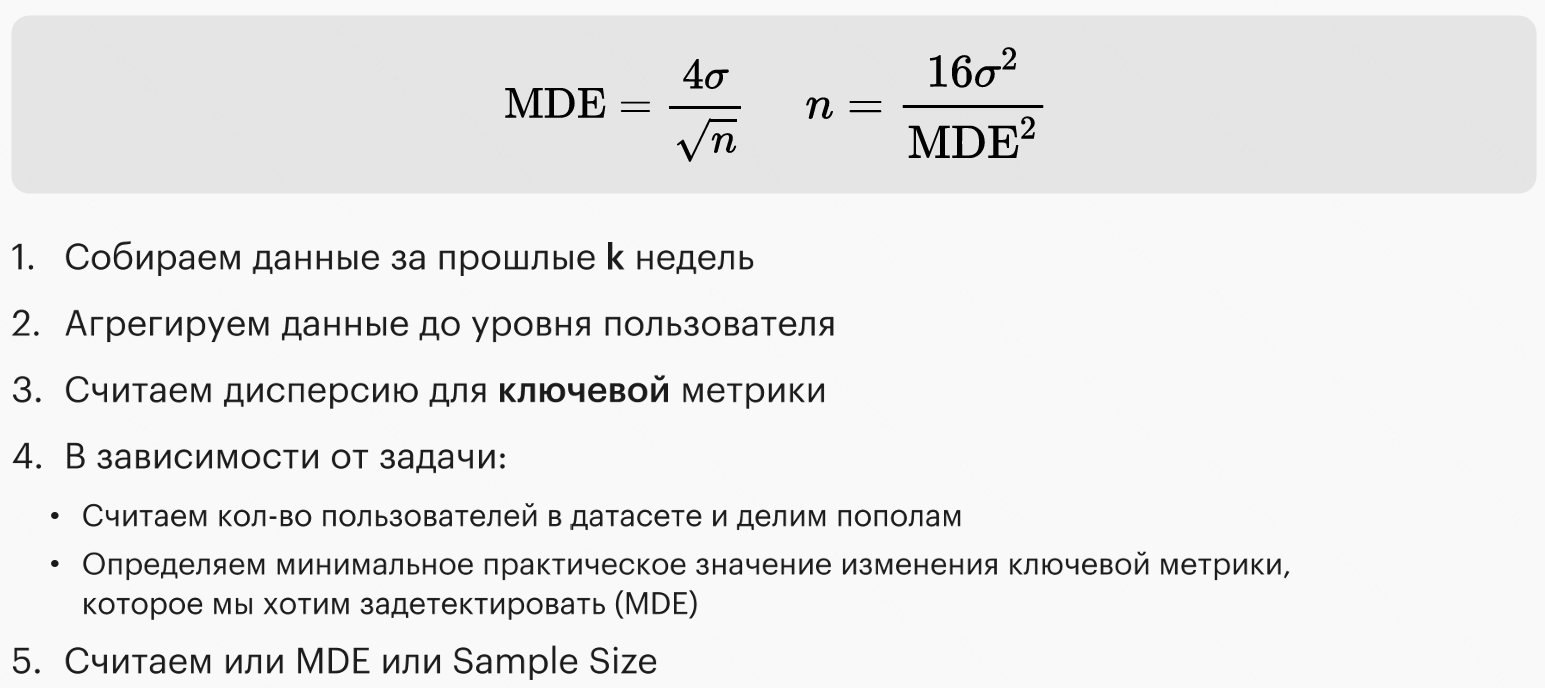

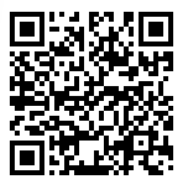